Clean IF images

In [1]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('/home/martinha/PycharmProjects/phd/Preprocess_IMC')

import os
import sys
from glob import glob
import numpy as np
from src.file_specs import FileSpecifics
import src.ImagePreprocessFilters as IPrep
import src.ImageParser as IP
import argparse

***Clean IF images with PENGUIN***

In [2]:

def preprocess_image(img, thresholds, percentiles):
    img = img.squeeze()
    filtered_img = np.empty(img.shape)
    
    for ch in range(img.shape[2]):
        img_ch = img[:, :, ch]
        # Thresholding
        th = thresholds[ch]
        if th is not None:
            img_ch = np.where(img_ch >= th, img_ch, 0)

        # Percentile filtering
        perc = percentiles[ch]
        if perc is not None:
            img_ch = img_ch[..., np.newaxis]
            img_ch = IPrep.percentile_filter(img_ch, window_size=3, percentile=perc, transf_bool=True)
            img_ch = img_ch.squeeze()

        filtered_img[:, :, ch] = img_ch
    return filtered_img



Number of images identified: 24


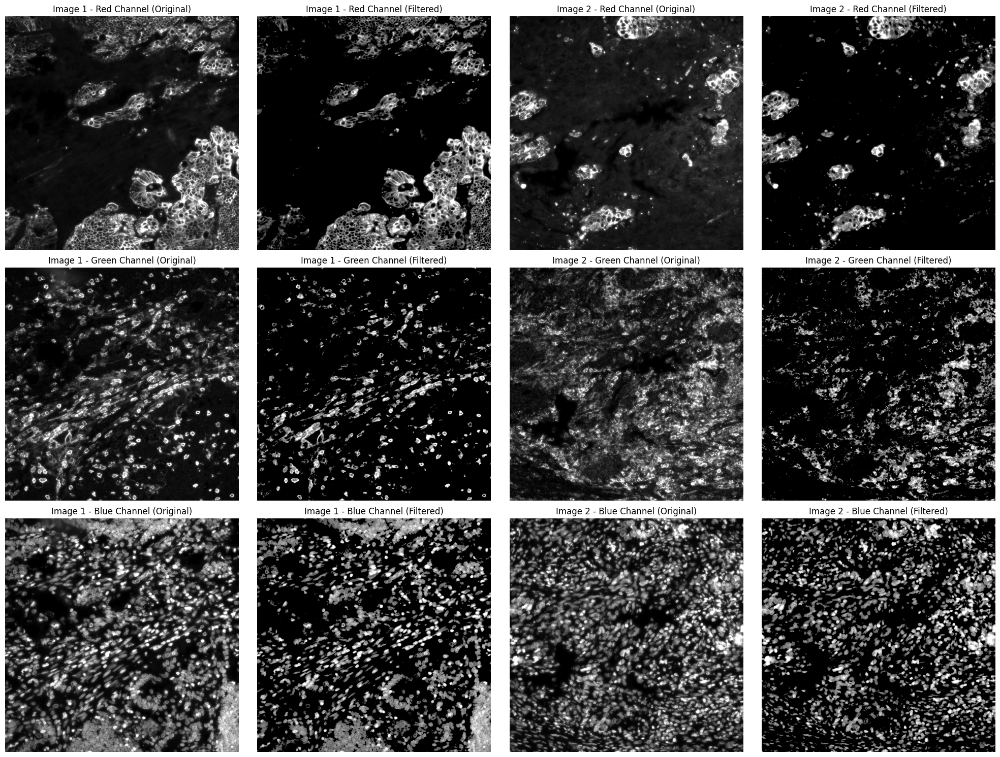

Displaying images at indices: 17 and 15


In [34]:


path_to_IF = "/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/composites"

folder_path = path_to_IF
path_for_results =  "/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/PENGUINcomposites"
# normalization outliers
up_limit = 99
down_limit = 1
binary_masks = False

# Load files
files = glob(os.path.join(folder_path, '*.tiff'))
num_images = len(files)
print(f"Number of images identified: {num_images}")

num_channels = 3
# Calculate thresholds and percentiles
thresholds = [0.2, 0.3, 0.3]
percentiles = [50, 10, 25]

images_original = list(map(IP.parse_image_pages, files))

# Preprocessing
imgs_out = map(lambda p: IPrep.remove_outliers(p, up_limit, down_limit), images_original)
imgs_norm = map(IPrep.normalize_channel_cv2_minmax, imgs_out)
filtered_images = map(lambda i: preprocess_image(i, thresholds, percentiles), imgs_norm)
imgs_filtered = list(filtered_images)

# Apply binary masks if needed
# imgs_filtered = [np.where(a > 0, 1, 0) for a in imgs_filtered]

# Select 2 random images
np.random.seed(42)  # for reproducibility
# np.random.seed(34)  # for reproducibility

random_indices = np.random.choice(len(images_original), size=2, replace=False)

# Get the images
img1_original = images_original[random_indices[0]]
img1_filtered = imgs_filtered[random_indices[0]]

img2_original = images_original[random_indices[1]]
img2_filtered = imgs_filtered[random_indices[1]]

# Create the plot: 3 rows (one per channel) x 4 columns (img1 pre, img1 post, img2 pre, img2 post)
fig, axes = plt.subplots(3, 4, figsize=(20, 15))

channel_names = ['Red Channel', 'Green Channel', 'Blue Channel']

for ch in range(3):  # For each channel
    # Image 1 - Before
    axes[ch, 0].imshow(img1_original[:, :, ch], cmap='gray')
    axes[ch, 0].set_title(f'Image 1 - {channel_names[ch]} (Original)')
    axes[ch, 0].axis('off')
    
    # Image 1 - After
    axes[ch, 1].imshow(img1_filtered[:, :, ch], cmap='gray')
    axes[ch, 1].set_title(f'Image 1 - {channel_names[ch]} (Filtered)')
    axes[ch, 1].axis('off')
    
    # Image 2 - Before
    axes[ch, 2].imshow(img2_original[:, :, ch], cmap='gray')
    axes[ch, 2].set_title(f'Image 2 - {channel_names[ch]} (Original)')
    axes[ch, 2].axis('off')
    
    # Image 2 - After
    axes[ch, 3].imshow(img2_filtered[:, :, ch], cmap='gray')
    axes[ch, 3].set_title(f'Image 2 - {channel_names[ch]} (Filtered)')
    axes[ch, 3].axis('off')

plt.tight_layout()
plt.show()

print(f"Displaying images at indices: {random_indices[0]} and {random_indices[1]}")

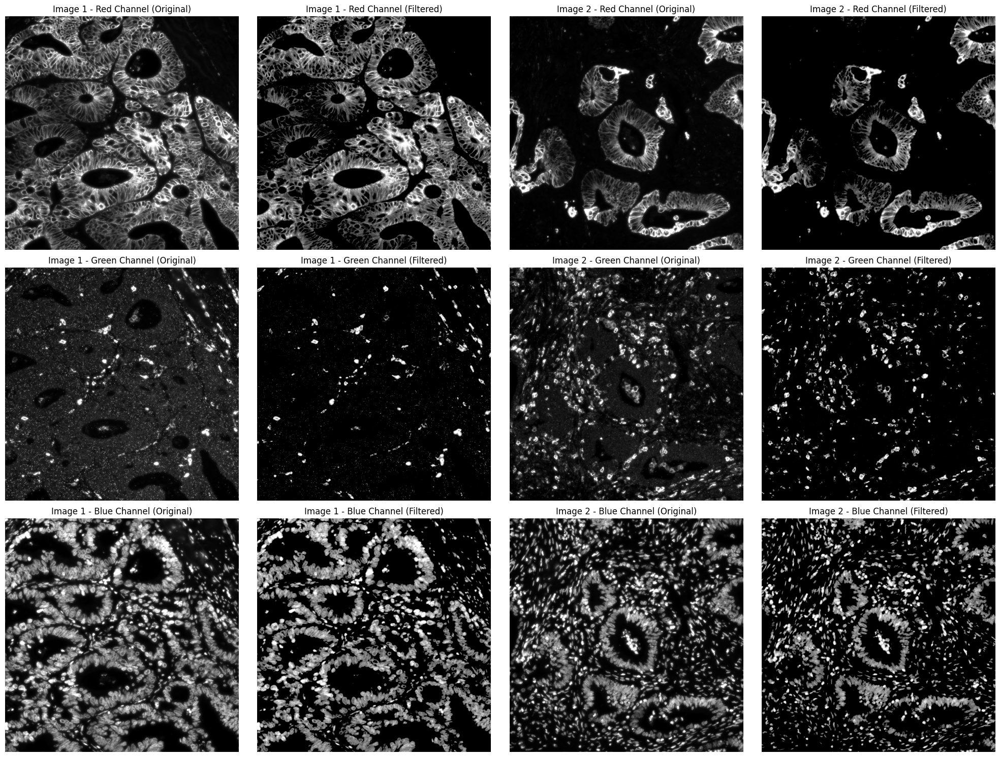

Displaying images at indices: 8 and 16


In [35]:

# Select 2 random images
np.random.seed(42)  # for reproducibility
# np.random.seed(34)  # for reproducibility

random_indices = np.random.choice(len(images_original), size=2, replace=False)

# Get the images
img1_original = images_original[random_indices[0]]
img1_filtered = imgs_filtered[random_indices[0]]

img2_original = images_original[random_indices[1]]
img2_filtered = imgs_filtered[random_indices[1]]

# Create the plot: 3 rows (one per channel) x 4 columns (img1 pre, img1 post, img2 pre, img2 post)
fig, axes = plt.subplots(3, 4, figsize=(20, 15))

channel_names = ['Red Channel', 'Green Channel', 'Blue Channel']

for ch in range(3):  # For each channel
    # Image 1 - Before
    axes[ch, 0].imshow(img1_original[:, :, ch], cmap='gray')
    axes[ch, 0].set_title(f'Image 1 - {channel_names[ch]} (Original)')
    axes[ch, 0].axis('off')
    
    # Image 1 - After
    axes[ch, 1].imshow(img1_filtered[:, :, ch], cmap='gray')
    axes[ch, 1].set_title(f'Image 1 - {channel_names[ch]} (Filtered)')
    axes[ch, 1].axis('off')
    
    # Image 2 - Before
    axes[ch, 2].imshow(img2_original[:, :, ch], cmap='gray')
    axes[ch, 2].set_title(f'Image 2 - {channel_names[ch]} (Original)')
    axes[ch, 2].axis('off')
    
    # Image 2 - After
    axes[ch, 3].imshow(img2_filtered[:, :, ch], cmap='gray')
    axes[ch, 3].set_title(f'Image 2 - {channel_names[ch]} (Filtered)')
    axes[ch, 3].axis('off')

plt.tight_layout()
plt.show()

print(f"Displaying images at indices: {random_indices[0]} and {random_indices[1]}")

save preprocessed figures 

In [45]:
# Save images
names_save = [os.path.join(path_for_results, os.path.basename(sub)) for sub in files]
os.makedirs(path_for_results, exist_ok=True)

for img, name in zip(imgs_filtered, names_save):
    IPrep.save_images(img, name, ch_last=True)

print(f'Images saved at {path_for_results}')

Images saved at /home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/PENGUINcomposites


### IMC preprocessing

IMC has more channels than 3. so we will check first

In [7]:
folder_path = "/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/xenium_imc_data"
path_for_results =  "/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/PENGUINcompositesIMC"
# normalization outliers
up_limit = 99
down_limit = 1
binary_masks = False

# Load files
files = glob(os.path.join(folder_path, '*.tiff'))
num_images = len(files)
print(f"Number of images identified: {num_images}")


specs = FileSpecifics(files[0], multitiff=True)
channel_names = specs.channel_names
print('Channel names: ', channel_names)
num_channels = len(channel_names)
print(num_channels)

Number of images identified: 3
Channel names:  ['80Ar(ArAr80Di)', 'TGFb(Y89Di)', 'IFNy(In115Di)', '127I(I127Di)', '131Xe(Xe131Di)', '134Xe(Xe134Di)', '138Ba(Ba138Di)', 'HLA-DR(Pr141Di)', 'CD20(Nd142Di)', 'CD68(Nd143Di)', 'CD11b(Nd144Di)', 'CD4(Nd145Di)', 'CD8a(Nd146Di)', 'CD31(Sm147Di)', 'TCRgd(Nd148Di)', 'CD45(Sm149Di)', 'GranzymeB(Nd150Di)', 'CD57(Eu151Di)', 'Ki-67(Sm152Di)', 'CD3(Eu153Di)', 'IgG1(Sm154Di)', 'CD138(Gd155Di)', 'PDL1(Gd156Di)', 'CD39(Gd157Di)', 'VISTA(Gd158Di)', 'FOXP3(Tb159Di)', 'PD-1(Gd160Di)', 'ICOS(Dy161Di)', 'IDO(Dy162Di)', 'CD14(Dy163Di)', 'CD204(Dy164Di)', 'CD45RO(Ho165Di)', 'D2-40(Er166Di)', 'CD56(Er167Di)', 'CD103(Er168Di)', 'CD38(Tm169Di)', 'Tbet(Er170Di)', 'CD15(Yb171Di)', 'C_caspase3(Yb172Di)', 'CD163(Yb173Di)', 'CD7(Yb174Di)', 'CD27(Lu175Di)', 'CD11c(Yb176Di)', '190BCKG(BCKG190Di)', 'DNA1(Ir191Di)', 'DNA2(Ir193Di)', 'Vimentin(Pt194Di)', 'Bcatenin(Pt196Di)', 'Keratin(Pt198Di)', 'Histone(Bi209Di)']
50


In [22]:
imc_marker_params = {
    # calibration channels . doesnt matter
    '80Ar(ArAr80Di)': (0,0.9), 
    '127I(I127Di)': (0,0.9), 
    '131Xe(Xe131Di)': (0,0.9), 
    '134Xe(Xe134Di)': (0,0.9), 
    '138Ba(Ba138Di)': (0,0.9), 
    
    # parameters form PENGUIN paper 
    'TGFb(Y89Di)': (40, 0.2), 
    'HLA-DR(Pr141Di)': (50, 0.1),
    'CD20(Nd142Di)': (50, 0.1),
    'CD68(Nd143Di)': (40, 0.2),
    'CD11b(Nd144Di)': (50, 0.25),
    'CD4(Nd145Di)': (50, 0.2),
    'CD8a(Nd146Di)': (60, 0.25),
    'CD31(Sm147Di)': (50, 0.2),
    'TCRgd(Nd148Di)': (40, 0.1),
    'CD45(Sm149Di)': (50, 0.2),
    'GranzymeB(Nd150Di)': (40, 0.2),
    'CD57(Eu151Di)': (60, 0.2),
    'Ki-67(Sm152Di)': (50, 0.2),
    'CD3(Eu153Di)': (50, 0.1),
    'PDL1(Gd156Di)': (50, 0.3),
    'CD39(Gd157Di)': (40, 0.2),
    'VISTA(Gd158Di)': (50, 0.2),
    'FOXP3(Tb159Di)': (50, 0.1),
    'PD-1(Gd160Di)': (40, 0.2),
    'ICOS(Dy161Di)': (50, 0.1),
    'IDO(Dy162Di)': (30, 0.3),
    'CD14(Dy163Di)': (40, 0.1),
    'CD204(Dy164Di)': (50, 0.1),
    'CD45RO(Ho165Di)': (50, 0.2),
    'D2-40(Er166Di)': (50, 0.25),
    'CD56(Er167Di)': (50, 0.2),
    'CD103(Er168Di)': (30, 0.1),
    'CD38(Tm169Di)': (40, 0.2),
    'Tbet(Er170Di)': (60, 0.1),
    'CD15(Yb171Di)': (40, 0.25), 
    'C_caspase3(Yb172Di)': (40, 0.3), 
    'CD163(Yb173Di)': (40, 0.3),
    'CD7(Yb174Di)': (50, 0.2),
    'Vimentin(Pt194Di)': (40, 0.1),
    'Bcatenin(Pt196Di)': (60, 0.2),
    'Keratin(Pt198Di)': (50, 0.5),
    'CD11c(Yb176Di)': (40, 0.0),
    
    # channels not in PENGUIN paper. 
    'CD27(Lu175Di)':(50,0.1),
    '190BCKG(BCKG190Di)':(50,0.1),
    'IgG1(Sm154Di)':(50,0.1),
    'IFNy(In115Di)':(50,0.1),
    'CD138(Gd155Di)':(50,0.1),
    'DNA1(Ir191Di)':(50,0.3),
    'DNA2(Ir193Di)':(50,0.3),
    'Histone(Bi209Di)':(50,0.1),
}

In [23]:
def get_marker(channel):
    return channel.split('(')[0]

# Create ordered lists using list comprehension
percentiles = [imc_marker_params.get(get_marker(ch), (50, 0.2))[0] for ch in channel_names]
thresholds = [imc_marker_params.get(get_marker(ch), (50, 0.2))[1] for ch in channel_names]


In [24]:
images_original = list(map(IP.parse_image_pages, files))

# Preprocessing
imgs_out = map(lambda p: IPrep.remove_outliers(p, up_limit, down_limit), images_original)
imgs_norm = map(IPrep.normalize_channel_cv2_minmax, imgs_out)
filtered_images = map(lambda i: preprocess_image(i, thresholds, percentiles), imgs_norm)
imgs_filtered = list(filtered_images)
print(len(imgs_filtered))

3


Type of imgs_filtered: <class 'list'>
Length: 3


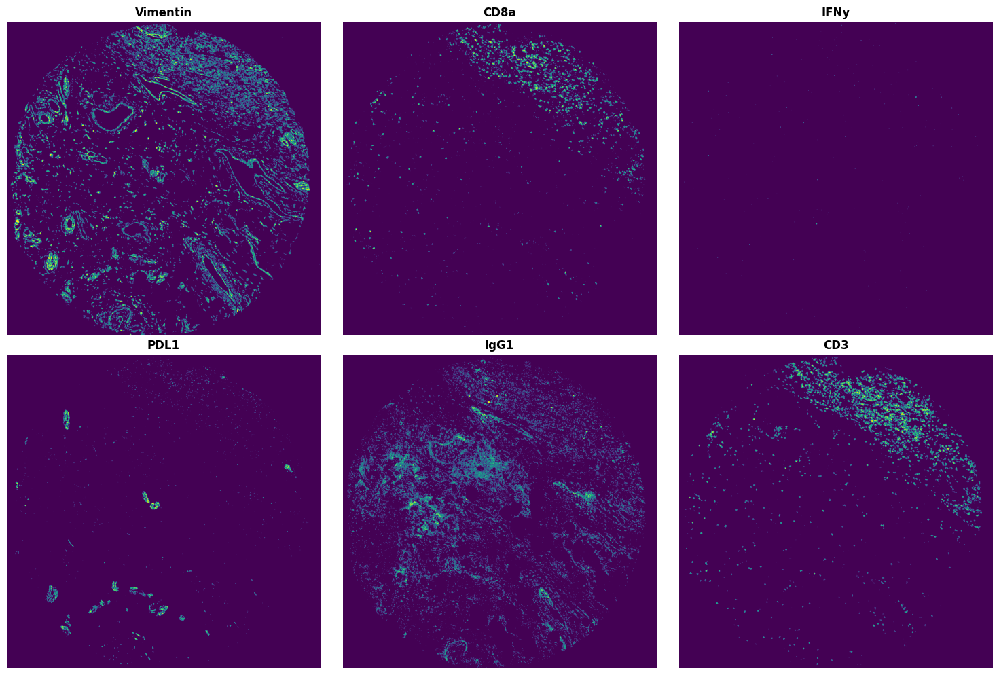

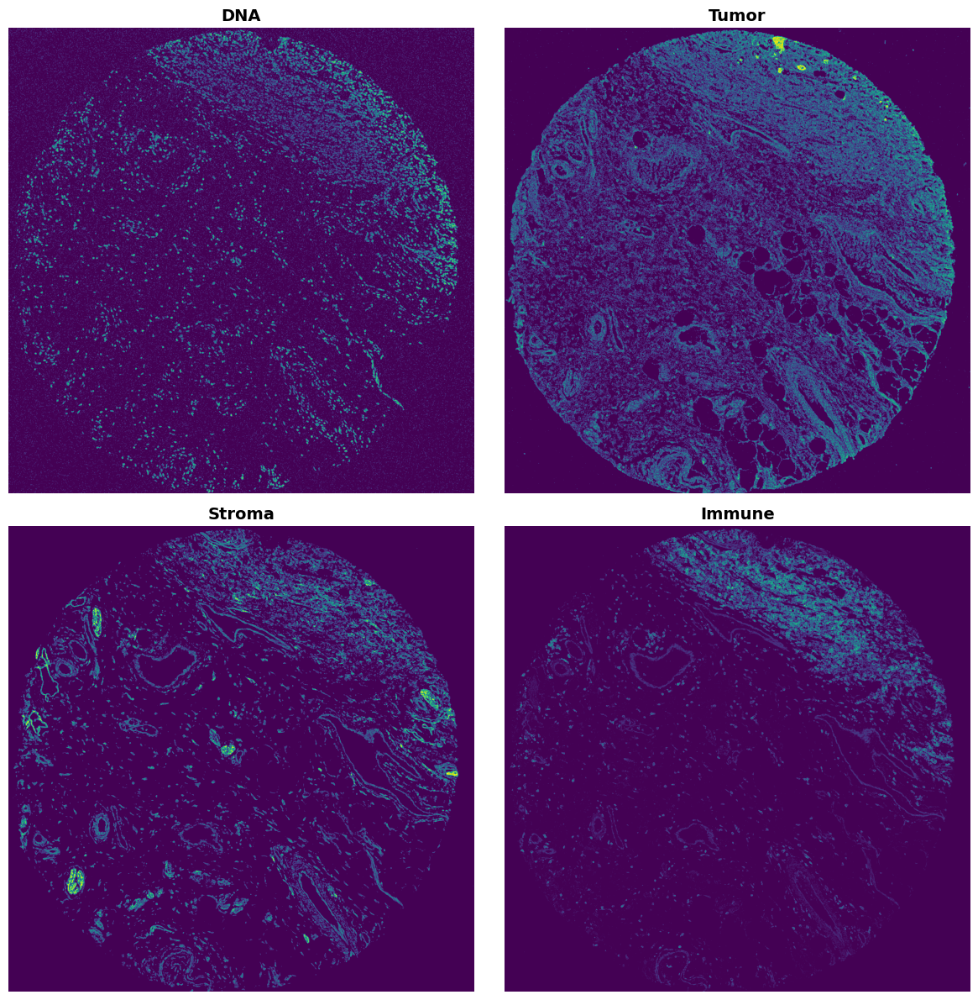

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Check what you have
print(f"Type of imgs_filtered: {type(imgs_filtered)}")
print(f"Length: {len(imgs_filtered) if hasattr(imgs_filtered, '__len__') else 'N/A'}")

# Simple version - just show 6 random markers for first image
def show_random_markers(img, channel_names, n=6):
    """Show n random markers from one image"""
    
    # Exclude calibration
    calib = ['80Ar', '127I', '131Xe', '134Xe', '138Ba', '190BCKG']
    valid = [i for i, ch in enumerate(channel_names) if not any(c in ch for c in calib)]
    
    # Pick random
    random.seed(42)
    indices = random.sample(valid, n)
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for i, idx in enumerate(indices):
        marker = channel_names[idx].split('(')[0]
        axes[i].imshow(img[:, :, idx], cmap='viridis')
        axes[i].set_title(marker, fontsize=12, fontweight='bold')
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()


# Show aggregated categories for one image
def show_aggregated(img, channel_names):
    """Show DNA, Tumor, Stroma, Immune aggregated"""
    
    categories = {
        'DNA': ['DNA1', 'DNA2', 'Histone'],
        'Tumor': ['Keratin', 'Bcatenin'],
        'Stroma': ['Vimentin', 'D2-40'],
        'Immune': ['CD45', 'CD3', 'CD4', 'CD8a', 'CD20', 'CD68']
    }
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    axes = axes.flatten()
    
    for i, (name, markers) in enumerate(categories.items()):
        # Sum channels that match these markers
        agg = np.zeros(img.shape[:2])
        for marker in markers:
            for j, ch in enumerate(channel_names):
                if marker in ch:
                    agg += img[:, :, j]
        
        axes[i].imshow(agg, cmap='viridis')
        axes[i].set_title(name, fontsize=14, fontweight='bold')
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()


# Use it (assuming imgs_filtered is a list of 3 images)
# If it's just one image:
if isinstance(imgs_filtered, np.ndarray):
    show_random_markers(imgs_filtered, channel_names)
    show_aggregated(imgs_filtered, channel_names)
# If it's a list:
elif isinstance(imgs_filtered, list) and len(imgs_filtered) > 0:
    show_random_markers(imgs_filtered[0], channel_names)
    show_aggregated(imgs_filtered[0], channel_names)

Generating random marker visualization...


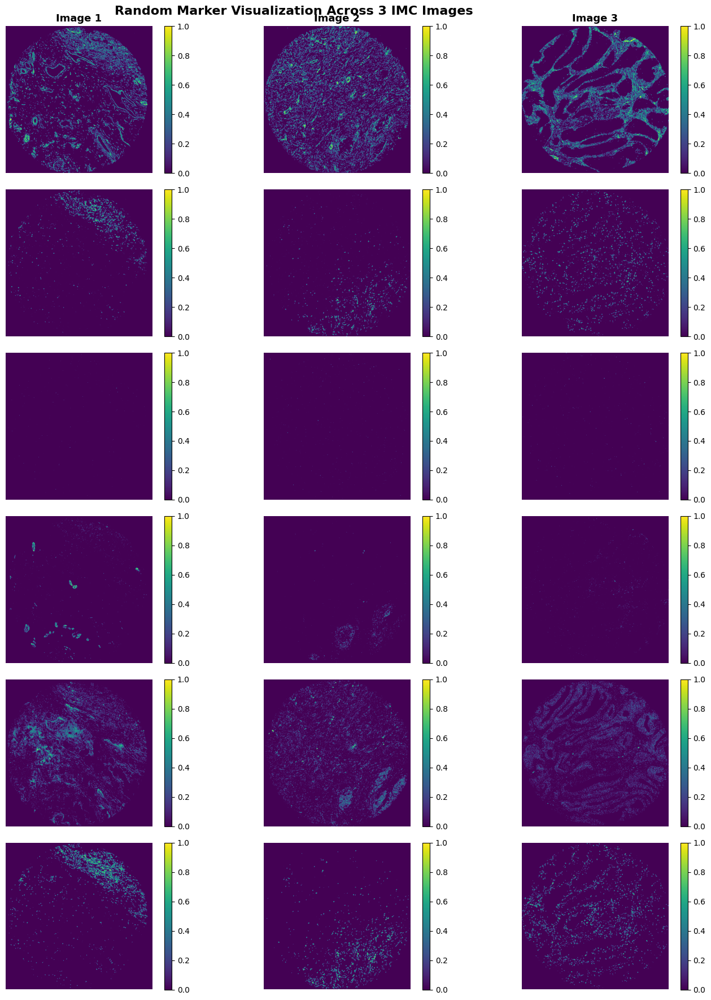

Displayed markers: ['Vimentin', 'CD8a', 'IFNy', 'PDL1', 'IgG1', 'CD3']

Generating aggregated marker visualization...


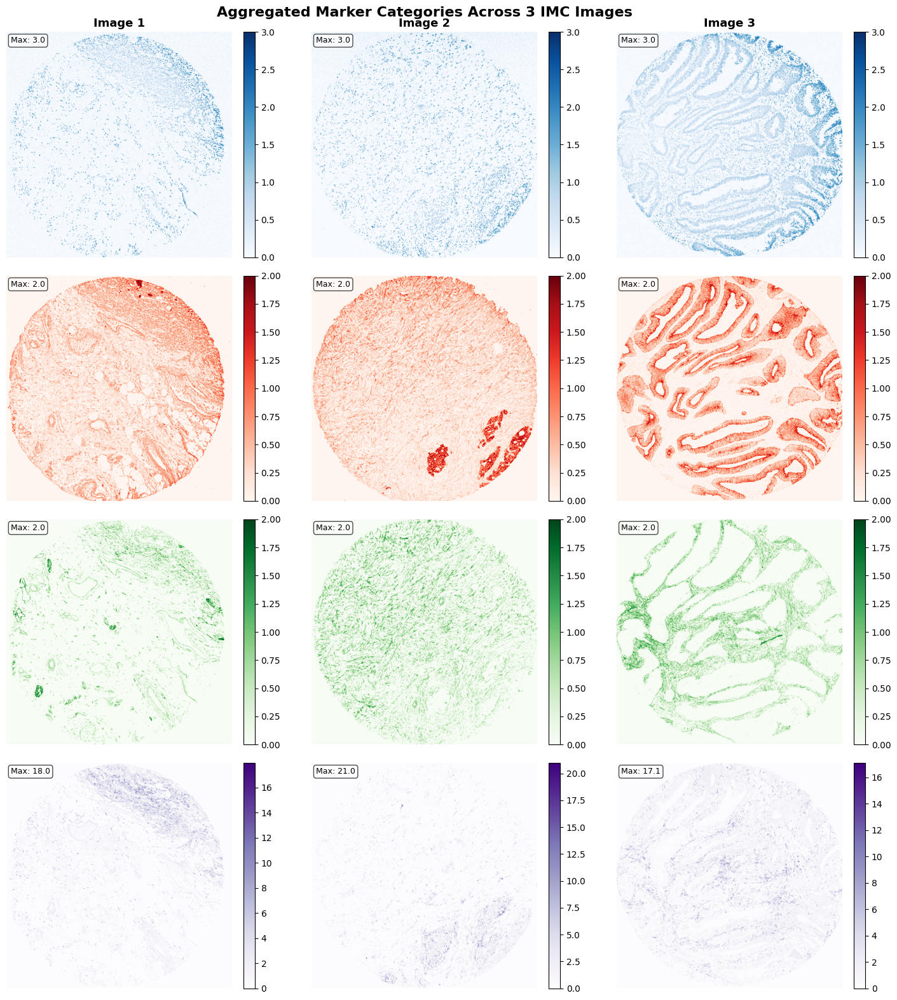


MARKER CATEGORIES SUMMARY

DNA: 3/3 markers present
  Markers: DNA1, DNA2, Histone...

Tumor: 2/2 markers present
  Markers: Keratin, Bcatenin...

Stroma: 2/2 markers present
  Markers: Vimentin, D2-40...

Immune: 36/36 markers present
  Markers: CD45, CD3, CD4, CD8a, CD20...


In [26]:
import matplotlib.pyplot as plt
import numpy as np
import random

# ============================================================================
# Define marker categories for aggregation
# ============================================================================

marker_categories = {
    'DNA': ['DNA1(Ir191Di)', 'DNA2(Ir193Di)', 'Histone(Bi209Di)'],
    
    'Tumor': ['Keratin(Pt198Di)', 'Bcatenin(Pt196Di)'],
    
    'Stroma': ['Vimentin(Pt194Di)', 'D2-40(Er166Di)'],
    
    'Immune': [
        'CD45(Sm149Di)', 'CD3(Eu153Di)', 'CD4(Nd145Di)', 'CD8a(Nd146Di)',
        'CD20(Nd142Di)', 'CD68(Nd143Di)', 'CD11b(Nd144Di)', 'CD11c(Yb176Di)',
        'TCRgd(Nd148Di)', 'CD14(Dy163Di)', 'CD163(Yb173Di)', 'CD204(Dy164Di)',
        'CD45RO(Ho165Di)', 'CD56(Er167Di)', 'CD7(Yb174Di)', 'CD57(Eu151Di)',
        'CD15(Yb171Di)', 'CD27(Lu175Di)', 'CD138(Gd155Di)', 'CD103(Er168Di)',
        'CD38(Tm169Di)', 'CD39(Gd157Di)', 'HLA-DR(Pr141Di)', 'FOXP3(Tb159Di)',
        'PD-1(Gd160Di)', 'PDL1(Gd156Di)', 'ICOS(Dy161Di)', 'VISTA(Gd158Di)',
        'GranzymeB(Nd150Di)', 'Tbet(Er170Di)', 'IFNy(In115Di)', 'TGFb(Y89Di)',
        'IDO(Dy162Di)', 'Ki-67(Sm152Di)', 'CD31(Sm147Di)', 'C_caspase3(Yb172Di)'
    ]
}

# Calibration channels to exclude
calibration_channels = [
    '80Ar(ArAr80Di)', '127I(I127Di)', '131Xe(Xe131Di)', 
    '134Xe(Xe134Di)', '138Ba(Ba138Di)', '190BCKG(BCKG190Di)'
]


# ============================================================================
# VISUALIZATION 1: Random individual markers across 3 images
# ============================================================================

def visualize_random_markers(images, channel_names, n_markers=6, seed=42):
    """
    Display 6 random markers across 3 IMC images
    """
    
    # Get non-calibration channels
    valid_channels = [ch for ch in channel_names if ch not in calibration_channels]
    
    # Select random markers
    random.seed(seed)
    selected_channels = random.sample(valid_channels, n_markers)
    selected_indices = [channel_names.index(ch) for ch in selected_channels]
    
    # Create plot
    fig, axes = plt.subplots(n_markers, len(images), figsize=(15, 3*n_markers))
    
    for row, (channel, idx) in enumerate(zip(selected_channels, selected_indices)):
        marker_name = channel.split('(')[0]
        
        for col, img in enumerate(images):
            ax = axes[row, col] if n_markers > 1 else axes[col]
            
            # Display channel
            channel_data = img[:, :, idx]
            im = ax.imshow(channel_data, cmap='viridis')
            
            if col == 0:
                ax.set_ylabel(marker_name, fontsize=12, fontweight='bold')
            
            if row == 0:
                ax.set_title(f'Image {col+1}', fontsize=13, fontweight='bold')
            
            ax.axis('off')
            
            # Add colorbar
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    
    plt.suptitle('Random Marker Visualization Across 3 IMC Images', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print(f"Displayed markers: {[ch.split('(')[0] for ch in selected_channels]}")


# ============================================================================
# VISUALIZATION 2: Aggregated markers (DNA, Tumor, Stroma, Immune)
# ============================================================================

def aggregate_markers(image, channel_names, marker_list):
    """
    Sum channels for a list of markers
    """
    aggregated = np.zeros(image.shape[:2], dtype=np.float32)
    
    for marker in marker_list:
        if marker in channel_names:
            idx = channel_names.index(marker)
            aggregated += image[:, :, idx]
    
    return aggregated


def visualize_aggregated_markers(images, channel_names):
    """
    Display DNA, Tumor, Stroma, and Immune aggregated markers for 3 images
    """
    
    categories = ['DNA', 'Tumor', 'Stroma', 'Immune']
    colors = ['Blues', 'Reds', 'Greens', 'Purples']
    
    fig, axes = plt.subplots(len(categories), len(images), figsize=(15, 16))
    
    for row, (category, cmap) in enumerate(zip(categories, colors)):
        marker_list = marker_categories[category]
        
        for col, img in enumerate(images):
            ax = axes[row, col]
            
            # Aggregate channels
            aggregated = aggregate_markers(img, channel_names, marker_list)
            
            # Display
            im = ax.imshow(aggregated, cmap=cmap)
            
            if col == 0:
                n_markers = len([m for m in marker_list if m in channel_names])
                ax.set_ylabel(f'{category}\n({n_markers} markers)', 
                             fontsize=12, fontweight='bold')
            
            if row == 0:
                ax.set_title(f'Image {col+1}', fontsize=13, fontweight='bold')
            
            ax.axis('off')
            
            # Add colorbar
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            
            # Add statistics
            ax.text(0.02, 0.98, f'Max: {aggregated.max():.1f}', 
                   transform=ax.transAxes, fontsize=9, 
                   verticalalignment='top', bbox=dict(boxstyle='round', 
                   facecolor='white', alpha=0.7))
    
    plt.suptitle('Aggregated Marker Categories Across 3 IMC Images', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print("\n" + "="*80)
    print("MARKER CATEGORIES SUMMARY")
    print("="*80)
    for category, markers in marker_categories.items():
        present = [m for m in markers if m in channel_names]
        print(f"\n{category}: {len(present)}/{len(markers)} markers present")
        print(f"  Markers: {', '.join([m.split('(')[0] for m in present[:5]])}...")


# ============================================================================
# Run visualizations (assuming you have loaded your 3 IMC images)
# ============================================================================

# Example - replace with your actual loaded images:
# imc_images = [image1, image2, image3]  # Each shape: (H, W, 50)

# Visualization 1: Random markers
print("Generating random marker visualization...")
visualize_random_markers(imgs_filtered, channel_names, n_markers=6, seed=42)

# Visualization 2: Aggregated categories
print("\nGenerating aggregated marker visualization...")
visualize_aggregated_markers(imgs_filtered, channel_names)

In [33]:
len(imgs_filtered)

3

In [37]:
# Save images
names_save = [os.path.join(path_for_results, os.path.basename(sub)) for sub in files]
os.makedirs(path_for_results, exist_ok=True)

for i in range(3):
    IPrep.save_img_ch_names_pages(imgs_filtered[i], names_save[i], 
                                  ch_last=True, channel_names=channel_names)

print(f'Images saved at {path_for_results}')

    

Images saved at /home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/PENGUINcompositesIMC
